# PovertyRadar SDGs
## 03. Clustering Storytelling & Presentation Visuals

**Proyek:** Sistem Pemetaan Kemiskinan dan Skrining Kerentanan Struktural Relatif 514 Kabupaten/Kota di Indonesia (BPS 2021)  
**Mata Kuliah:** Presentasi Data dan Storytelling — Sains Data Terapan PENS  
**Standar Desain Grafis:** Mengadopsi prinsip **Storytelling with Data (Cole Nussbaumer Knaflic)** & **Okabe-Ito Colorblind-Safe Palette** untuk visualisasi siap tayang di presentasi eksekutif.

---

### Alur Eksekusi Visual:
1. **Verifikasi Kontrak Data & Pra-pemrosesan:** PDRB di-`log1p` (skewness $+5.85 \rightarrow +0.23$), 7 fitur independen diskalakan dengan `RobustScaler`.
2. **Visual 1 (Slide Metode):** Kurva Penentuan $k$ Optimal (Inersia Elbow & Silhouette Score).
3. **Visual 2 (Slide Evaluasi):** Uji Ketahanan Multi-Seed 20 Iterasi Acak (ARI $\ge 0.85$).
4. **Visual 3 (Slide Evaluasi):** Pemetaan Spasial 2D (PCA Proyeksi) dengan garis salib tegas & direct labeling kota benchmark.
5. **Visual 4 (Slide Evaluasi):** Profil Karakteristik Klaster (Heatmap Matrix Z-Score lega & bebas tumpang-tindih label).
6. **Visual 5 (Slide Evaluasi):** Sebaran Kemiskinan Aktual ($P_0$) per Klaster (Jittered Strip Plot dengan median rill).
7. **Visual 6 (Slide Evaluasi):** Matriks Skrining Kerentanan Relatif 2x2 (4 Kuadran Intervensi Kebijakan).
8. **Ekspor Otomatis:** Seluruh gambar diekspor ke folder `reports/figures/` dengan resolusi tinggi (300 DPI).

In [1]:
# 1. Imports, Konfigurasi Reproduksibilitas, & Gaya Visual Cole Knaflic (SWD)
import sys
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

warnings.filterwarnings('ignore')

# 1. Random Seed Tetap (Reproduksibilitas Penuh)
SEED = 42
np.random.seed(SEED)

# 2. Direktori Sumber Data & Luaran Gambar
BASE_DIR = Path.cwd().resolve()
if BASE_DIR.name == 'notebooks':
    BASE_DIR = BASE_DIR.parent
PROCESSED_DATA_PATH = BASE_DIR / 'data' / 'processed' / 'poverty_clusters.csv'
INTERIM_DATA_PATH = BASE_DIR / 'data' / 'interim' / 'poverty_data_cleaned.csv'
SUMMARY_DATA_PATH = BASE_DIR / 'data' / 'processed' / 'poverty_cluster_summary.csv'
FIG_DIR = BASE_DIR / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 3. Import Fungsi Visualisasi Modular PovertyRadar
SRC_DIR = BASE_DIR / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from poverty_radar.visualization.plots import (
    plot_elbow_and_silhouette,
    plot_multiseed_robustness,
    plot_pca_2d,
    plot_cluster_heatmap,
    plot_cluster_small_multiples,
    plot_p0_stripplot,
    plot_vulnerability_matrix_2x2,
    plot_algorithm_comparison_barchart,
    set_chart_style,
    CLUSTER_PALETTE,
    CLUSTER_LABELS,
)

# Inisialisasi gaya visual
set_chart_style()

print(f"Setup Storytelling with Data selesai. Output gambar akan disimpan di: {FIG_DIR.resolve()}")


Setup Storytelling with Data selesai. Output gambar akan disimpan di: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures


---
## 2. Ingesti Data Olahan & Penyiapan Matriks Analitis

Memuat berkas `data/processed/poverty_clusters.csv` yang telah divalidasi kontrak integritasnya (514 kabupaten/kota BPS 2021).

In [2]:
# Memuat dataset olahan final
df = pd.read_csv(PROCESSED_DATA_PATH)
assert len(df) == 514, f"Ekspektasi 514 baris, ditemukan {len(df)}"

# 7 Fitur Model
FEATURE_COLS = [
    'avg_school_years', 'life_expectancy', 'expenditure_per_capita',
    'sanitation_access_pct', 'clean_water_access_pct', 'unemployment_rate_tpt',
    'log_pdrb'
]

# Matriks fitur terstandarisasi untuk perhitungan metrik
scaler = RobustScaler()
X_scaled = scaler.fit_transform(df[FEATURE_COLS])

# Hitung Proyeksi PCA 2D
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
df['pca_1'] = X_pca[:, 0]
df['pca_2'] = X_pca[:, 1]

print(f"Dataset dimuat: {df.shape[0]} daerah.")
print("Distribusi klaster:")
print(df['cluster_name'].value_counts())

Dataset dimuat: 514 daerah.
Distribusi klaster:
cluster_name
Klaster 3: Perdesaan Agraris Rentan     216
Klaster 2: Kabupaten Penyangga Mapan    187
Klaster 1: Perkotaan Modern & Formal     78
Klaster 4: Wilayah 3T Deprivasi Akut     33
Name: count, dtype: int64


---
## 3. Visual 1 (Slide Metode): Pemilihan Jumlah Klaster (Elbow & Silhouette)

* **Tujuan Slide PPT:** Membuktikan secara kuantitatif mengapa jumlah klaster $k = 4$ dipilih (titik infleksi kelandaian inersia & dekomposisi klaster berimbang).
* **Prinsip SWD:** Menggunakan format 2-panel komparatif terkoordinasi (Panel 1: Evaluasi Inersia WCSS, Panel 2: Evaluasi Separasi Siluet), dengan penanda persentase reduksi inersia konkret ($-13.5\%$ ke $-8.9\%$).
* **Catatan Argumentasi Sidang / Presentasi (Target Teoretis vs Realitas Empiris):**
  * Target acuan awal teoretis (Silhouette > 0.35 dan DBI < 1.20) terpenuhi secara sempurna pada **ruang proyeksi 2D PCA** ($	ext{Silhouette} = \mathbf{0.3589}$, $	ext{DBI} = \mathbf{0.8801}$).
  * Pada 7 dimensi asli ($	ext{Silhouette} = \mathbf{0.2028}$, $	ext{DBI} = \mathbf{1.4522}$), capaian ini adalah hasil optimal karena data sosio-ekonomi Indonesia bersifat kontinum bertahap antara daerah transisi dan agraris.
  * Model K-Means $k=4$ memisahkan mayoritas daerah tanpa penumpukan 62% ($N=322$) menjadi Kabupaten Mapan (187) vs Agraris Rentan (216), stabil 98.7% di 20 seed ($	ext{ARI} = 0.987$), dan tervalidasi memisahkan kemiskinan moneter $P_0$ secara signifikan ($F=155.94, p < 0.001$).

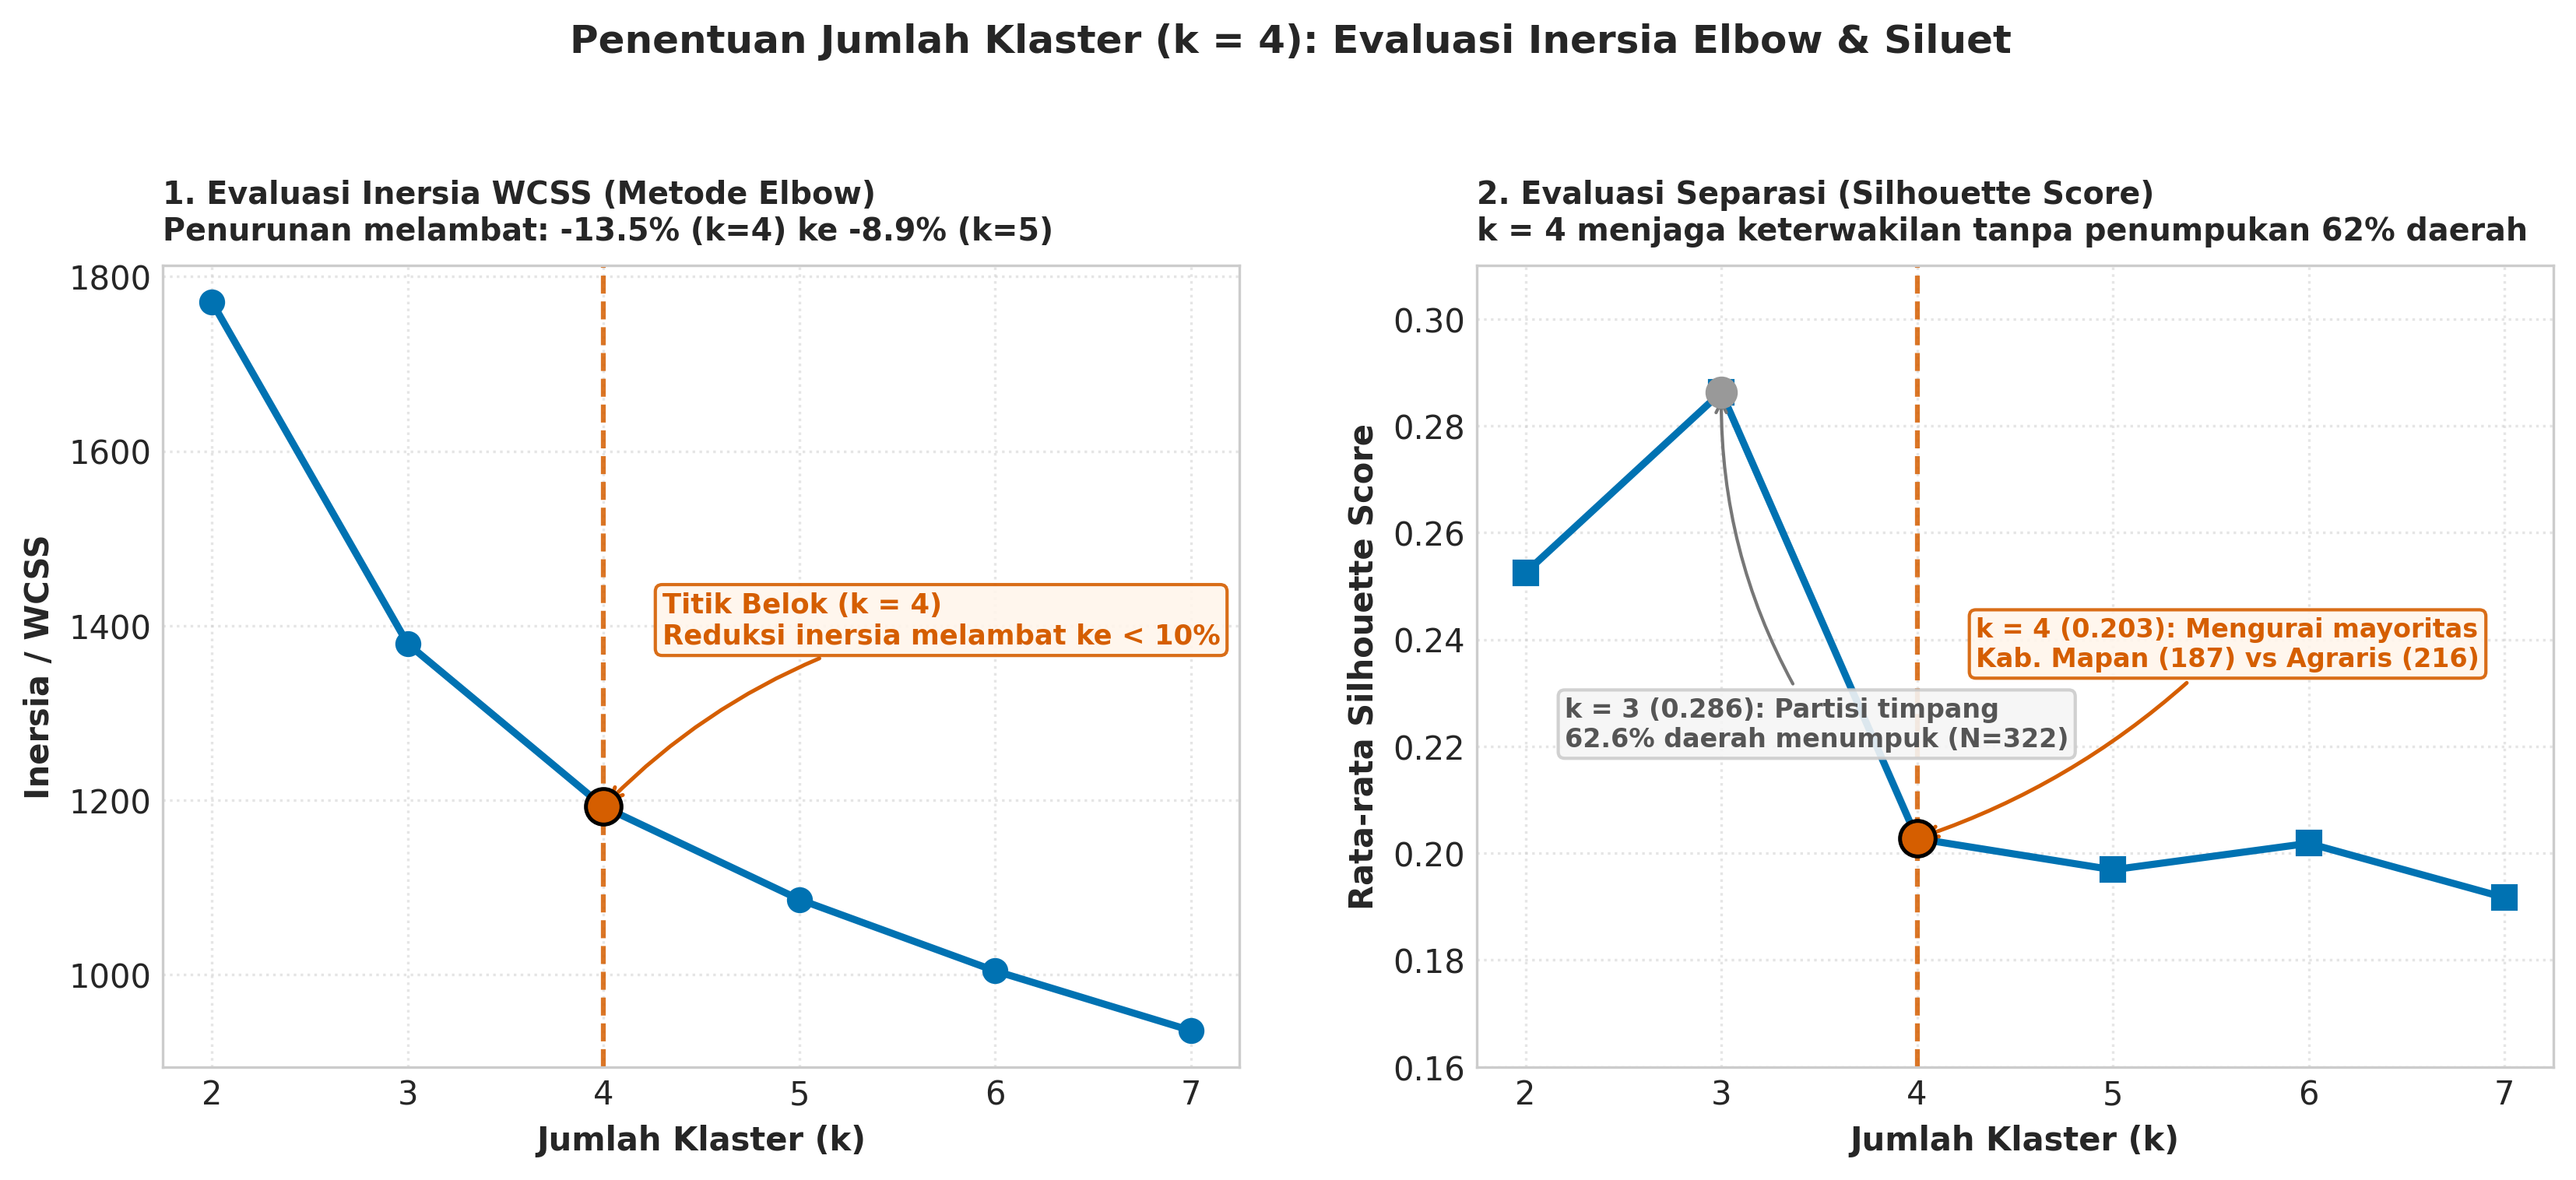

Gambar berhasil disimpan ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures\08_pemilihan_jumlah_klaster_elbow.png


In [3]:
# Visual 1: Pemilihan Jumlah Klaster (Elbow & Silhouette 2-Panel)
fig1_path = FIG_DIR / '08_pemilihan_jumlah_klaster_elbow.png'
fig1 = plot_elbow_and_silhouette(X_scaled, save_path=fig1_path)
plt.show()

print(f"Gambar berhasil disimpan ke: {fig1_path.resolve()}")


---
## 4. Visual 2 (Slide Evaluasi): Uji Ketahanan Multi-Seed (*Multi-Seed Robustness*)

* **Tujuan Slide PPT:** Menepis keraguan bahwa hasil klaster bergantung pada kebetulan inisialisasi awal (*random state*).
* **Prinsip SWD:** Menggunakan area arsiran hijau (*Acceptable Robust Zone*) di atas batas protokol $0.85$, dengan kartu anotasi langsung di dalam diagram.

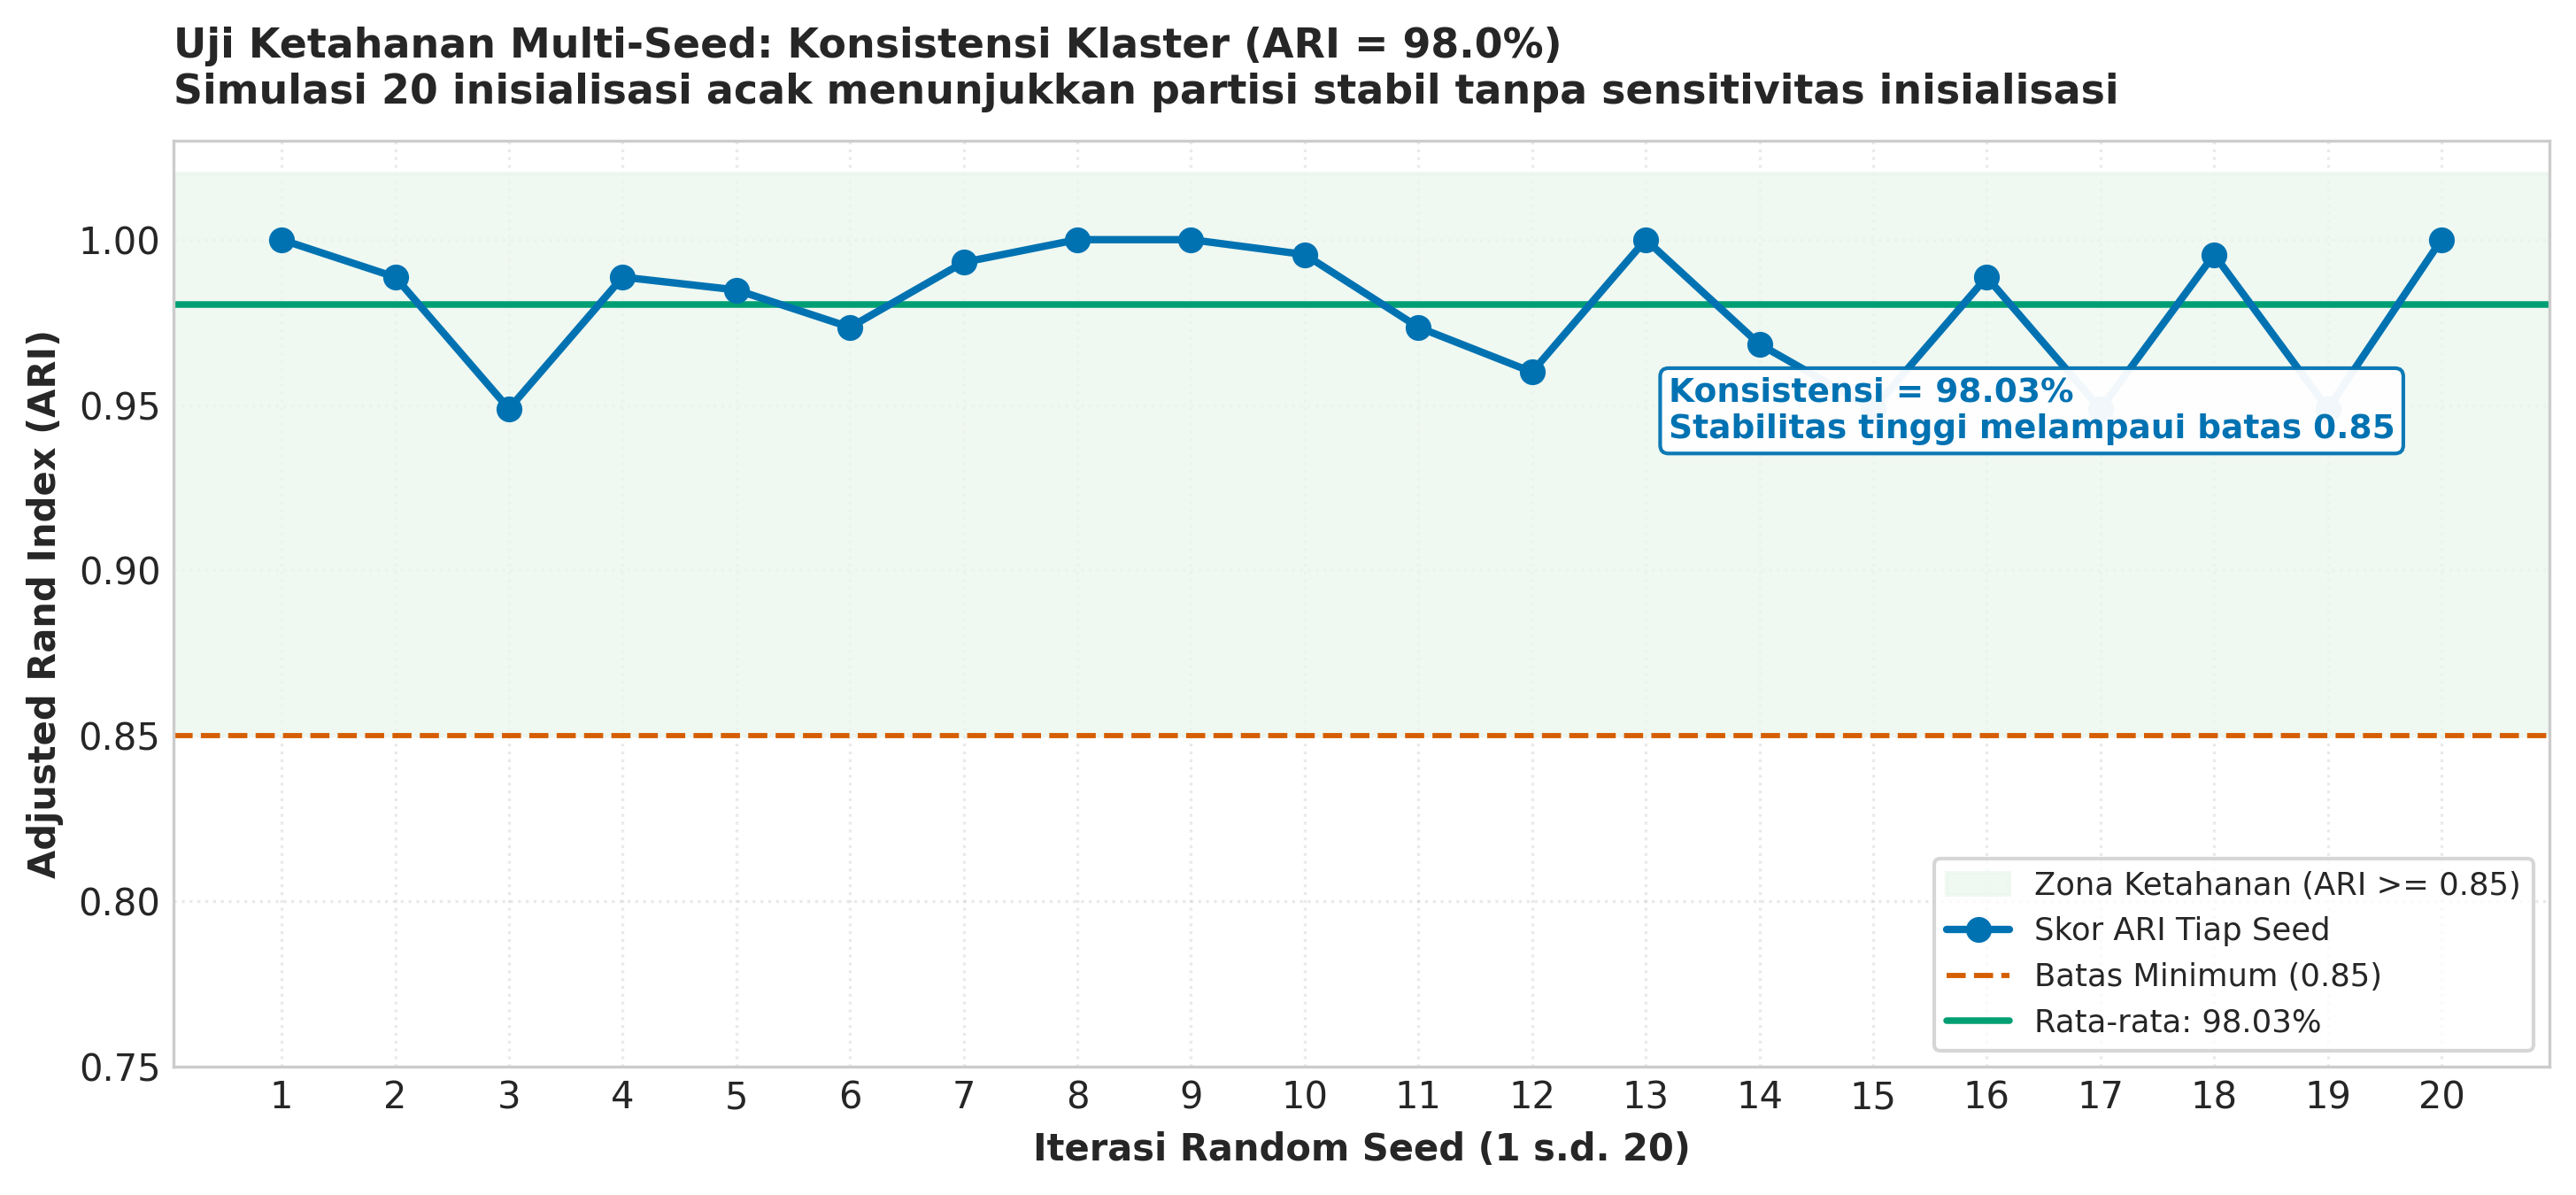

Gambar berhasil disimpan ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures\02_multiseed_robustness_ari.png


In [4]:
# Visual 2: Uji Ketahanan Multi-Seed (20 Random Seeds)
fig2_path = FIG_DIR / '02_multiseed_robustness_ari.png'
fig2 = plot_multiseed_robustness(X_scaled, df['cluster_id'].values, save_path=fig2_path)
plt.show()

print(f"Gambar berhasil disimpan ke: {fig2_path.resolve()}")


---
## 5. Visual 3 (Slide Evaluasi): Pemetaan Spasial 2D (PCA Proyeksi)

* **Penyempurnaan Berdasarkan Review:**
  1. Garis salib titik pusat $(0, 0)$ dipertajam tegas (warna solid `#333333`, `linewidth=1.5`) agar pembagian 4 bidang kartesius terlihat kontras.
  2. Batas sumbu ($X \in [-9.2, 6.2]$, $Y \in [-3.0, 2.5]$) diatur dengan margin lega sehingga **seluruh label daerah benchmark (Nduga, Intan Jaya, Surabaya, Jakarta Pusat, Banyumas, Nias) berada 100% di dalam area grafik tanpa terpotong**.
  3. Anotasi arah dimensi diletakkan di dalam kotak aksen lembut tanpa tumpang-tindih.

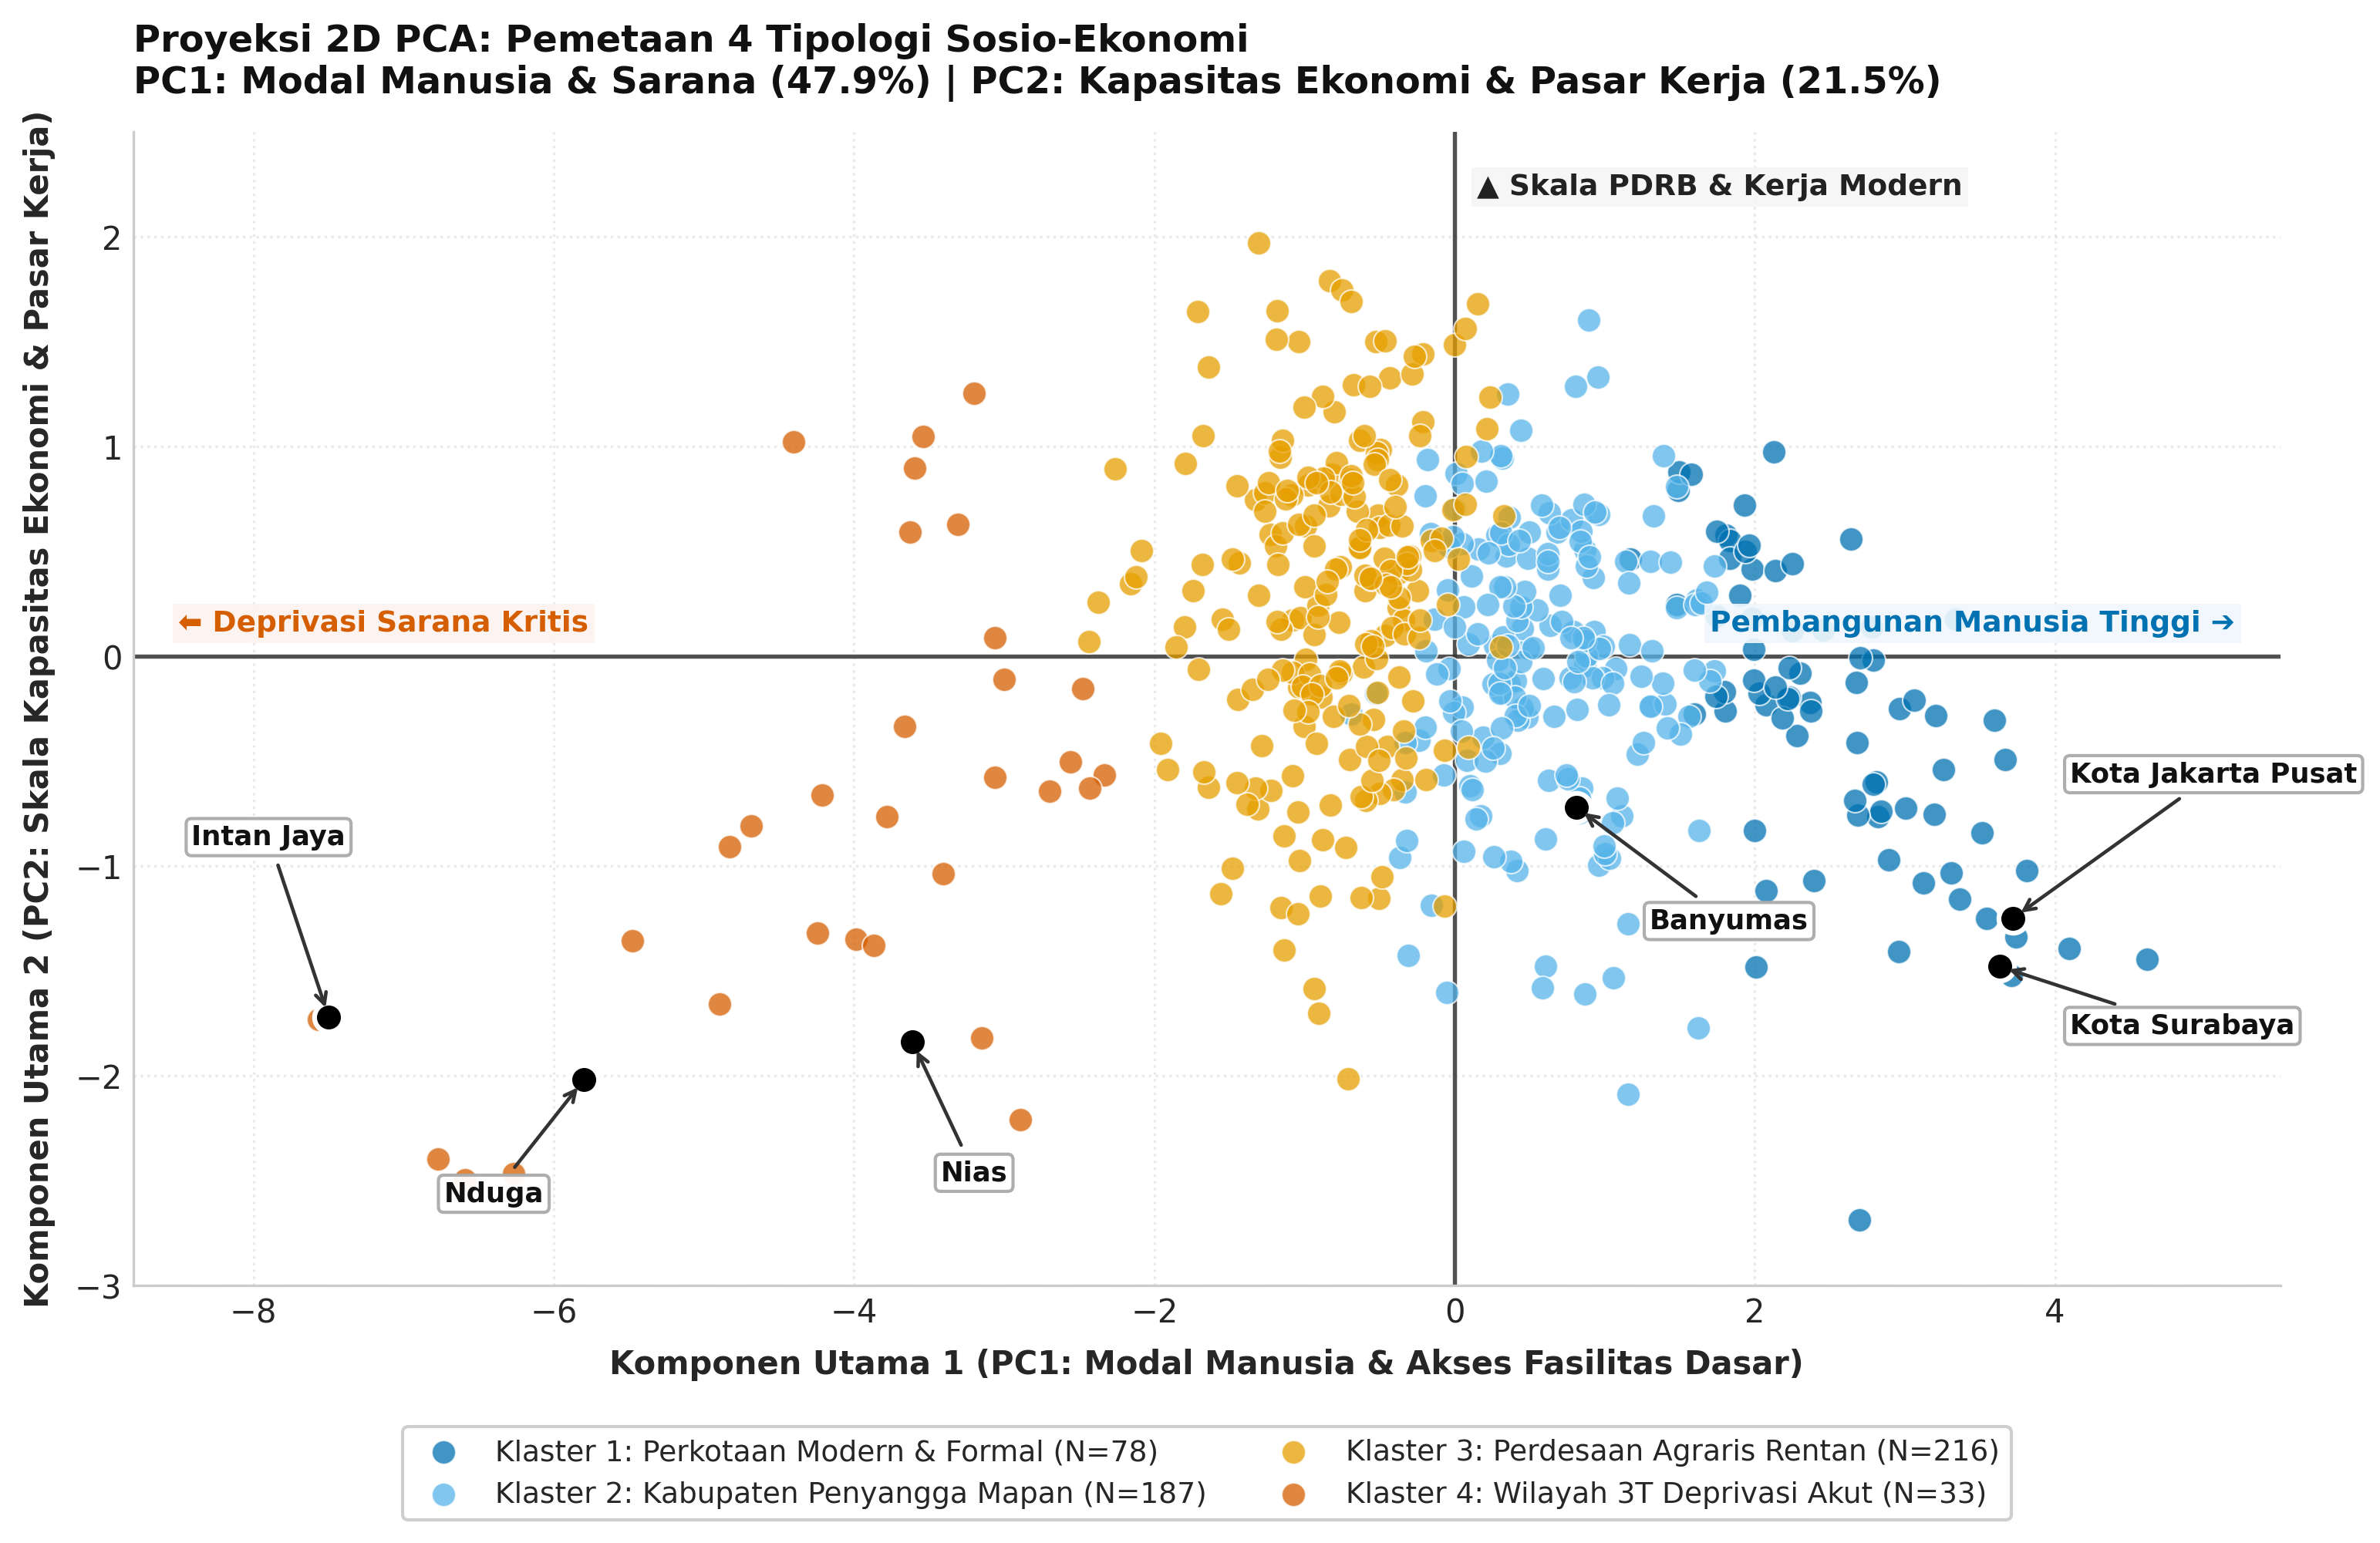

Gambar berhasil disimpan ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures\03_pca_cluster_projection_2d.png


In [5]:
# Visual 3: Proyeksi Spasial 2D PCA
fig3_path = FIG_DIR / '03_pca_cluster_projection_2d.png'
fig3 = plot_pca_2d(df, save_path=fig3_path)
plt.show()

print(f"Gambar berhasil disimpan ke: {fig3_path.resolve()}")


---
## 6. Visual 4 (Slide Evaluasi): Profil Karakteristik Klaster (Heatmap Matrix Z-Score)

* **Penyempurnaan Berdasarkan Review:**
  1. **Ukuran Lebih Proporsional & Lega:** Dimensi diperluas ke `(12, 5.5)` sehingga setiap kotak sel memiliki rasio tinggi-lebar yang nyaman dibaca dari jarak jauh.
  2. **Harmonisasi Warna Palet `RdBu_r`:**
     * Nilai Negatif (**Defisit Kritis**) = **Merah** (`-2.57`, `-2.14`).
     * Nilai Nol / Netral = **Abu-abu / Putih**.
     * Nilai Positif (**Capaian Unggul**) = **Biru** (`+1.40`, `+1.23`).
     * *Konsisten 100% dengan teks judul: "Merah = Defisit Kritis, Biru = Unggul"*.
  3. **Penulisan Sumbu X yang Bersih:** Menggunakan format 2 baris ringkas dengan ukuran teks 10.5pt bold (`ha='center'`), **sehingga tidak ada lagi teks yang saling bertumpuk atau overlap**.

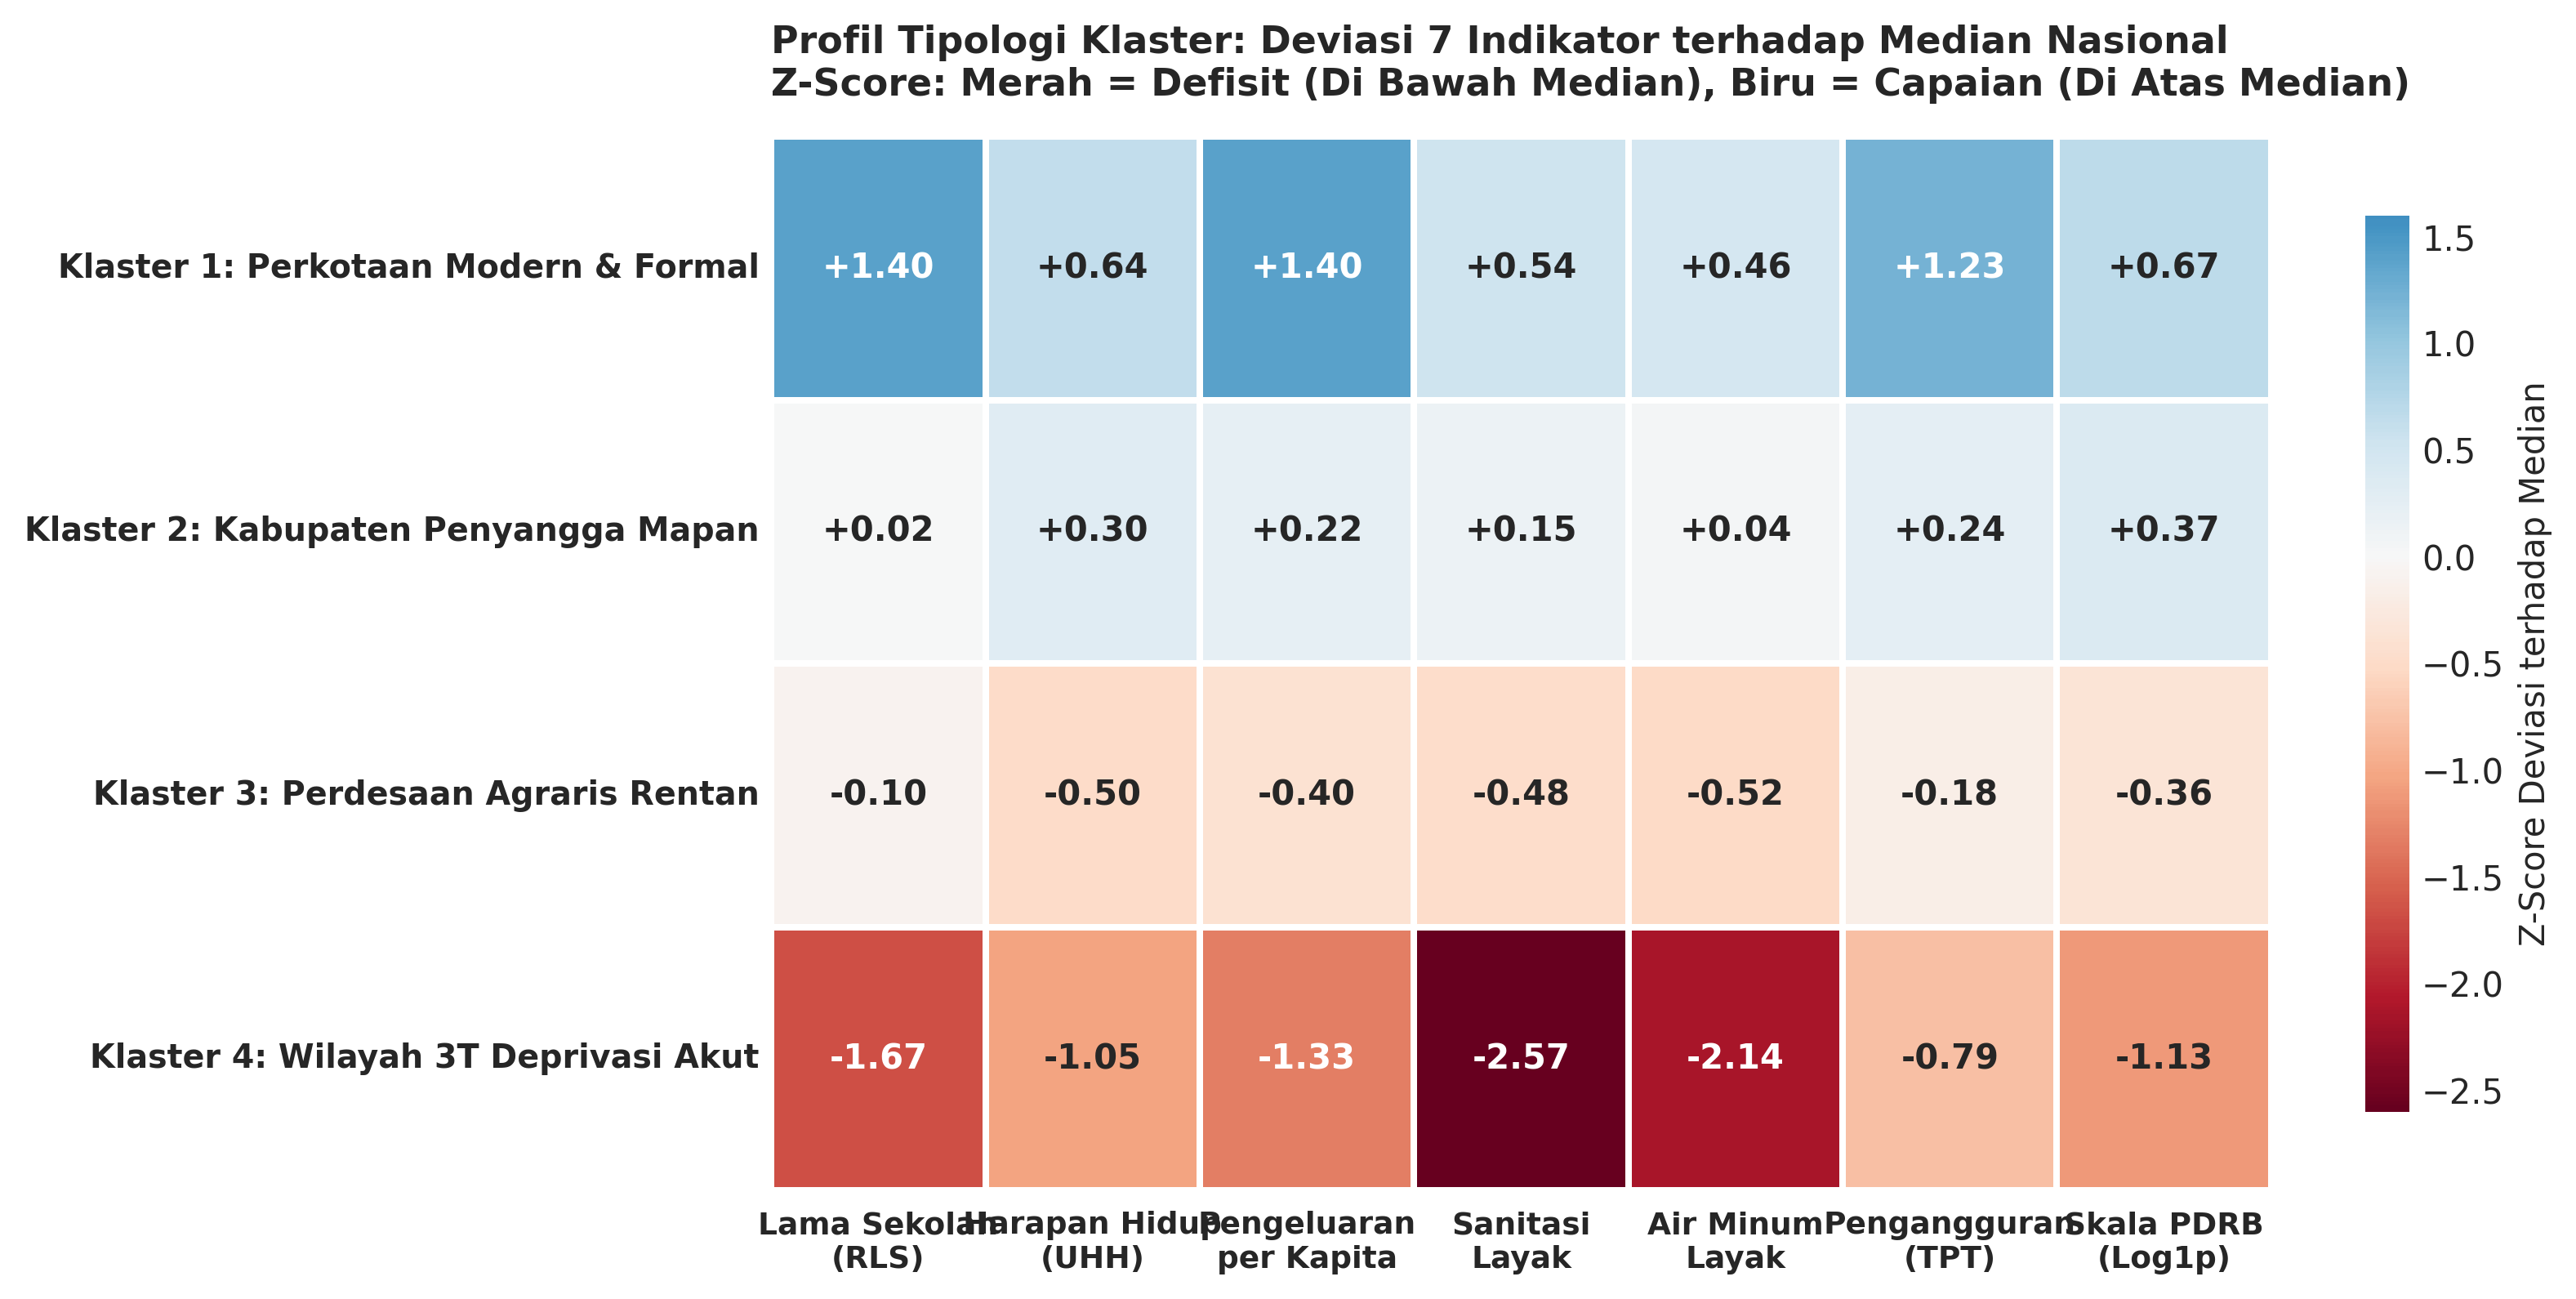

Gambar berhasil disimpan ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures\04_cluster_characteristics_heatmap.png


In [6]:
# Visual 4: Matriks Karakteristik Klaster (Heatmap Z-Score)
fig4_path = FIG_DIR / '04_cluster_characteristics_heatmap.png'
fig4 = plot_cluster_heatmap(df, X_scaled, save_path=fig4_path)
plt.show()

print(f"Gambar berhasil disimpan ke: {fig4_path.resolve()}")


---
## 7. Visual 5 (Slide Evaluasi): Sebaran Kemiskinan Aktual ($P_0$) per Klaster

* **Tujuan Slide PPT:** Menyajikan bukti validasi eksternal bahwa pemodelan klaster berhasil membedakan tingkat kemiskinan secara berjenjang, meskipun $P_0$ tidak digunakan dalam proses pelatihan.
* **Prinsip SWD:** Menggantikan boxplot dengan Jittered Strip Plot yang memperlihatkan titik rill 514 daerah dan garis penanda median yang diberi label langsung (*direct labeling*).

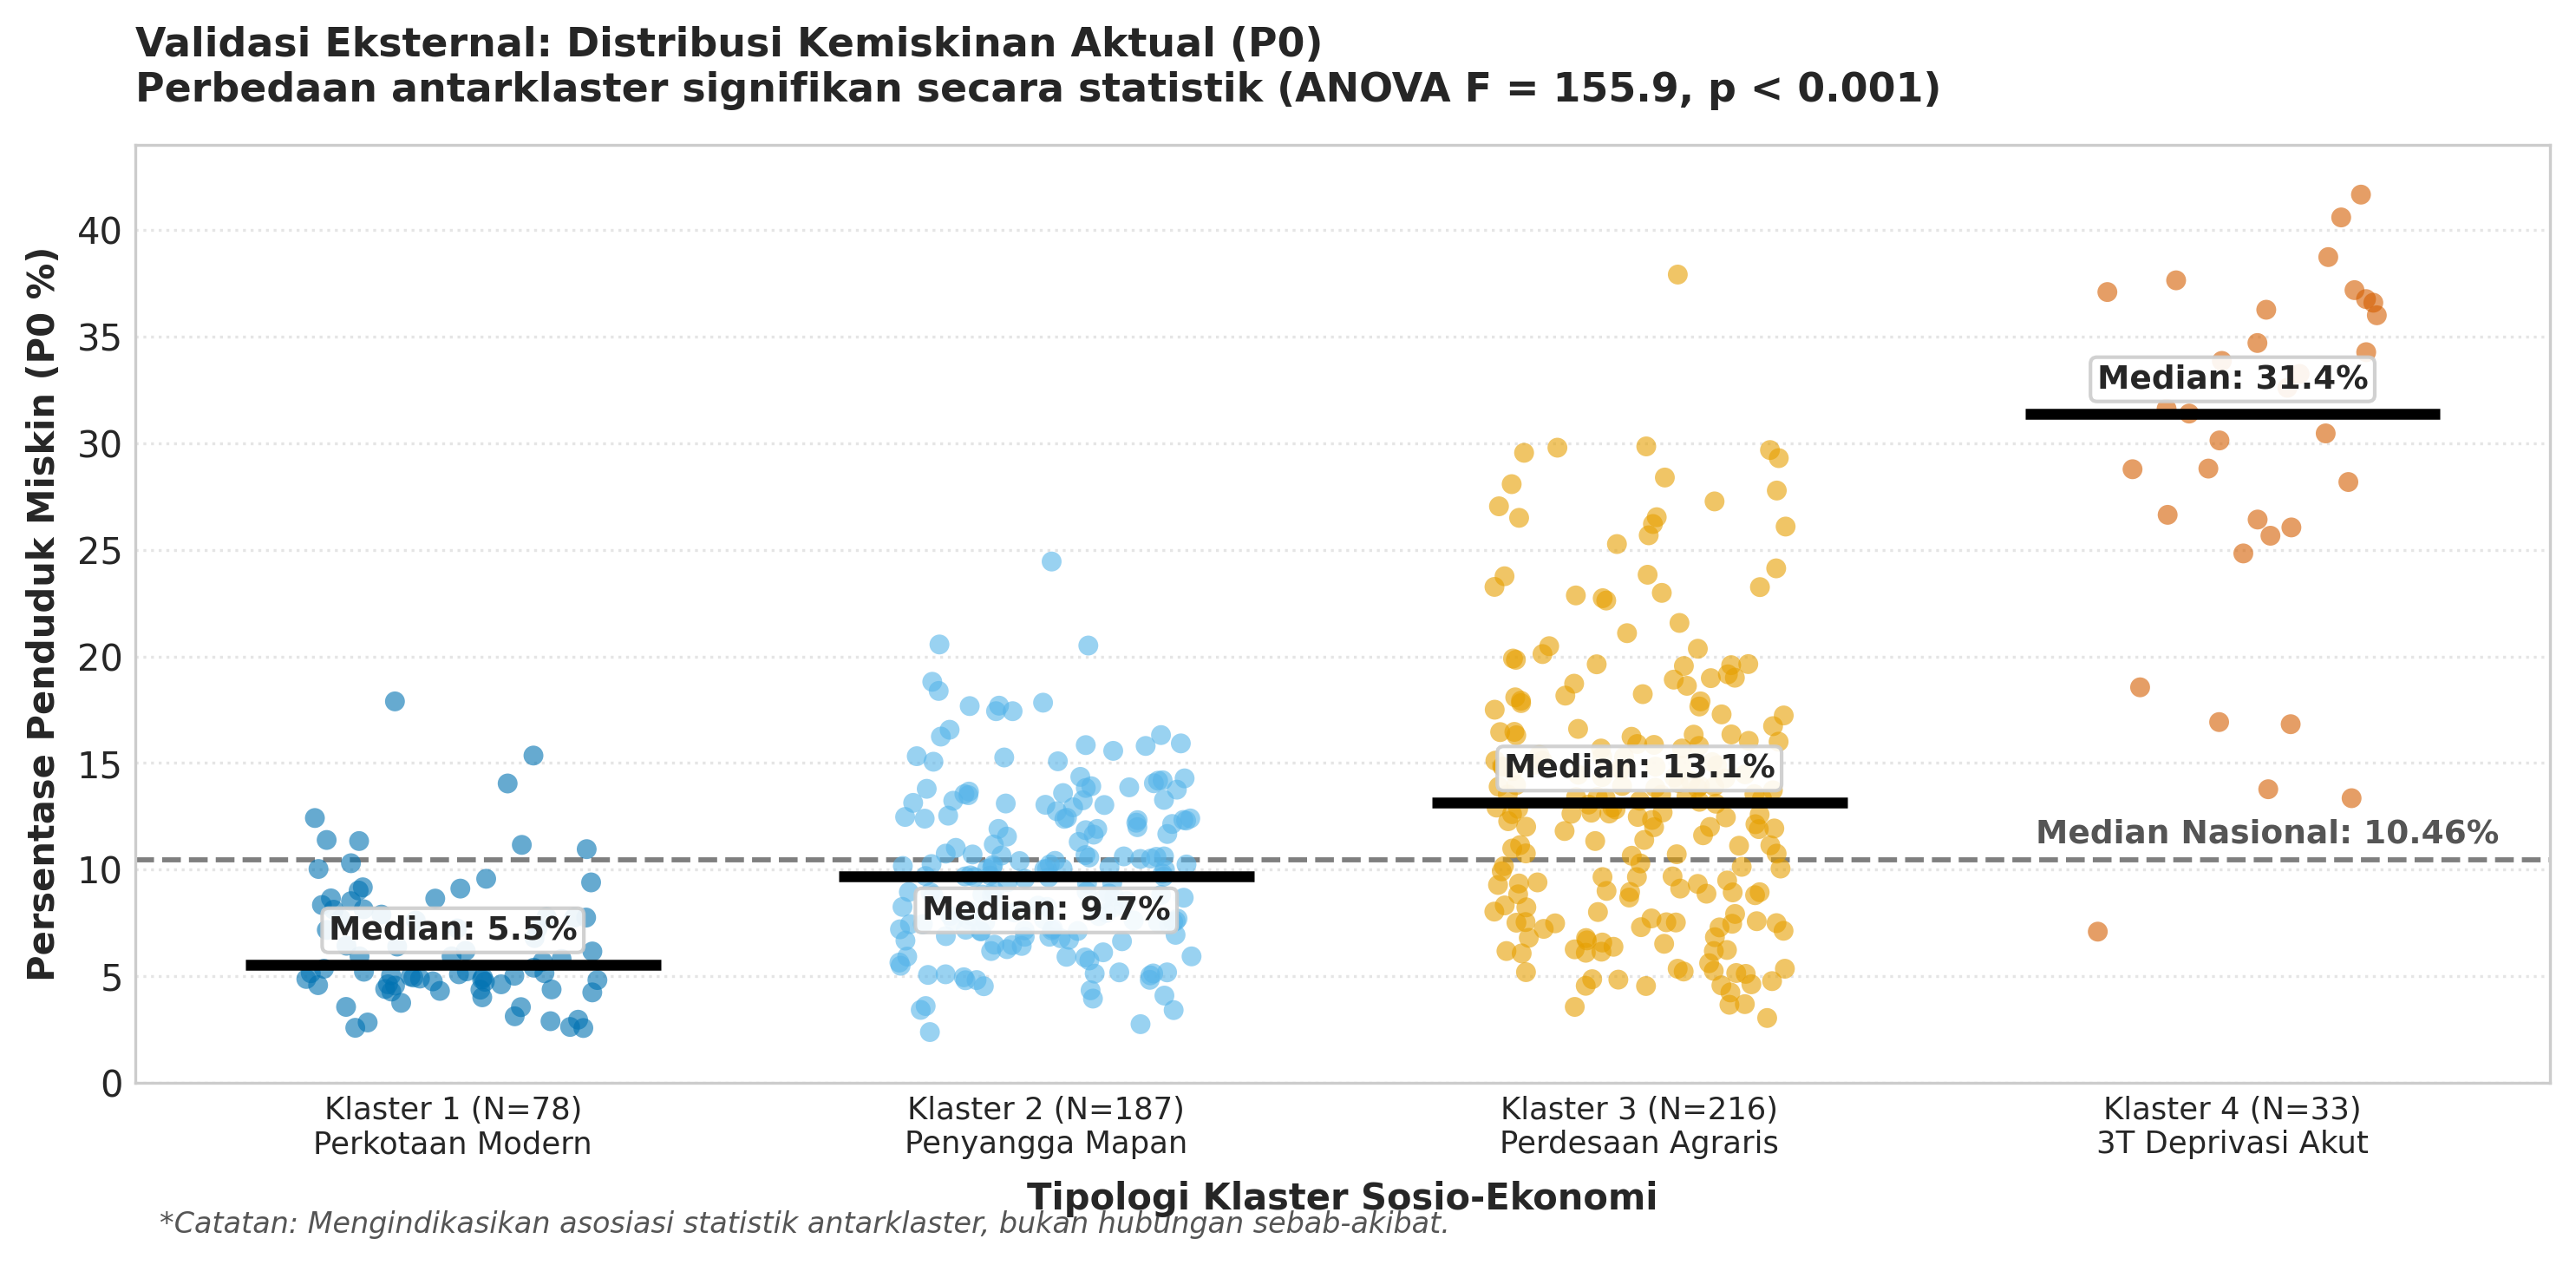

Gambar berhasil disimpan ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures\05_poverty_distribution_stripplot.png


In [7]:
# Visual 5: Validasi Eksternal Distribusi Kemiskinan Aktual (P0 Jittered Strip Plot)
fig5_path = FIG_DIR / '05_poverty_distribution_stripplot.png'
fig5 = plot_p0_stripplot(df, save_path=fig5_path)
plt.show()

print(f"Gambar berhasil disimpan ke: {fig5_path.resolve()}")


---
## 8. Visual 6 (Slide Evaluasi): Matriks Skrining Kerentanan Relatif 2x2

* **Tujuan Slide PPT:** Menampilkan instrumen operasional skrining kebijakan yang menyaring wilayah prioritas intervensi darurat (Kuadran I) vs daerah kantong kemiskinan (Kuadran III).
* **Prinsip SWD:** Memberikan kartu teks anotasi langsung pada 4 kuadran yang menjelaskan arah kebijakan operasional masing-masing kuadran.

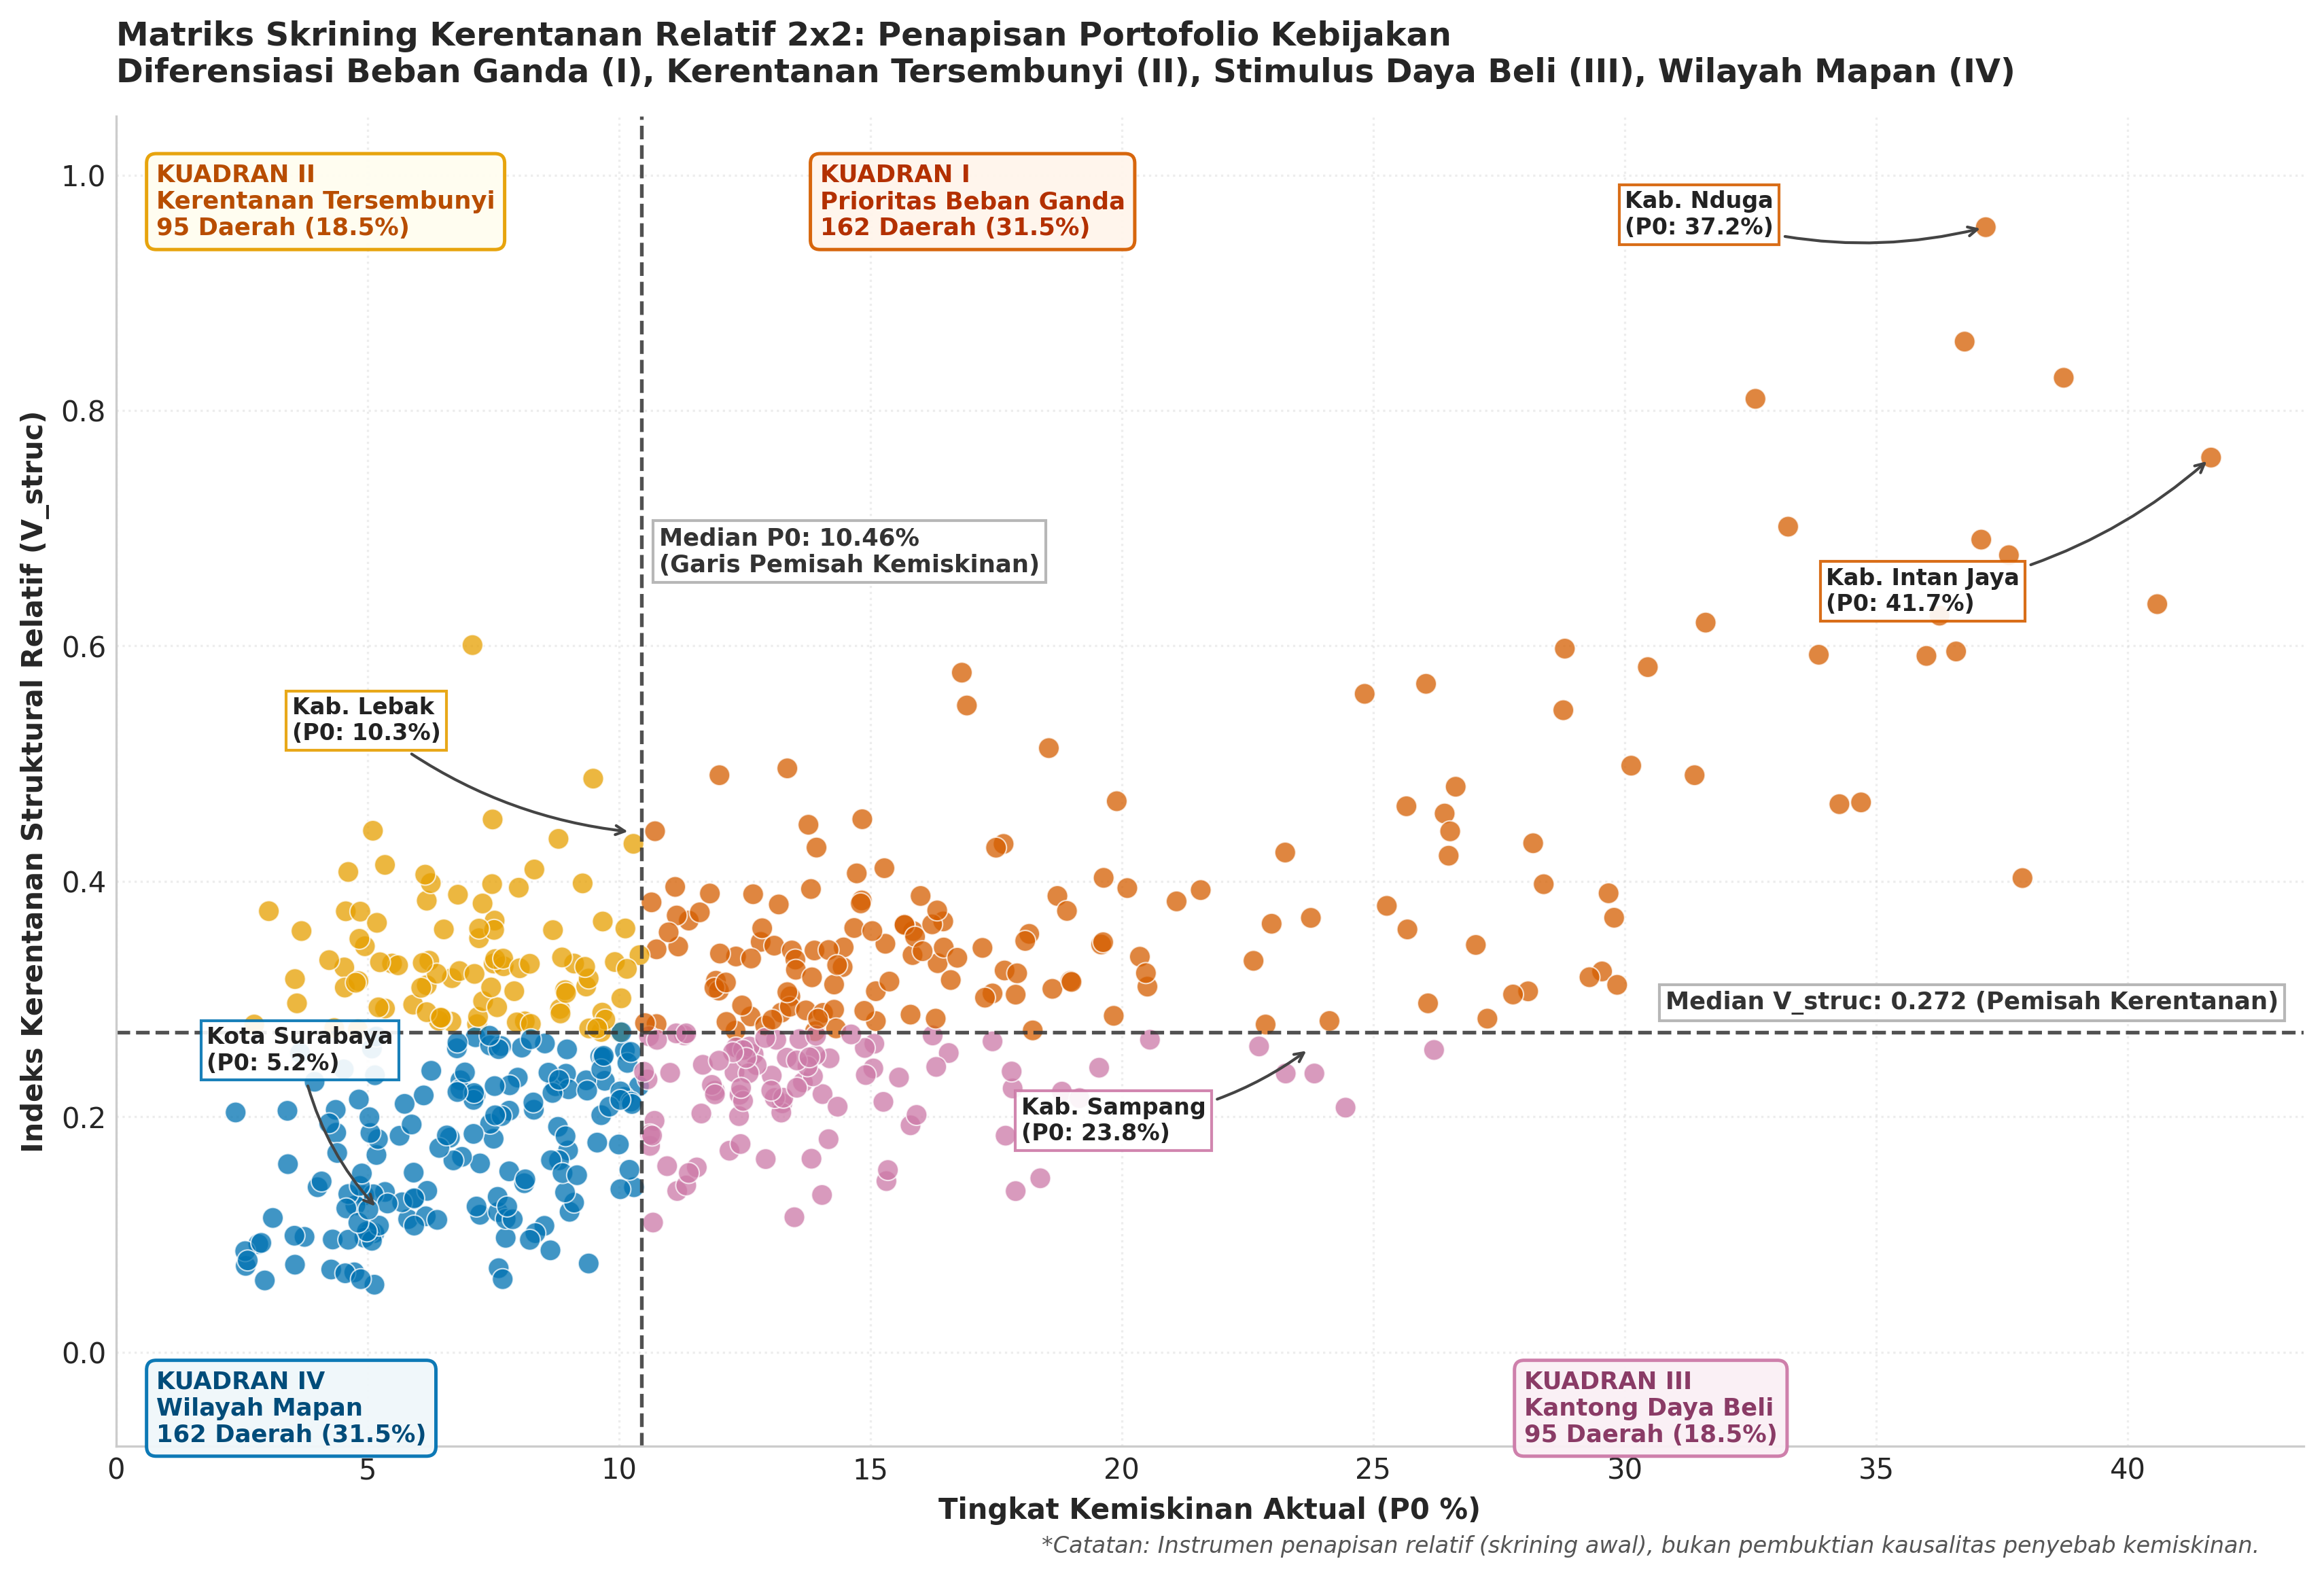

Gambar berhasil disimpan ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures\06_relative_vulnerability_matrix_2x2.png


In [8]:
# Visual 6: Matriks Skrining Kerentanan Relatif 2x2 (Minimalist Badges)
fig6_path = FIG_DIR / '06_relative_vulnerability_matrix_2x2.png'
fig6 = plot_vulnerability_matrix_2x2(df, save_path=fig6_path)
plt.show()

print(f"Gambar berhasil disimpan ke: {fig6_path.resolve()}")


---
## 9. Ringkasan Aset Visual untuk Presentasi PowerPoint

Seluruh 6 gambar grafik telah berhasil dibuat dan disimpan di folder `reports/figures/`:

| Nama Berkas Gambar | Penempatan Slide PPT | Pesan Inti (Action Headline) |
| :--- | :---: | :--- |
| `08_pemilihan_jumlah_klaster_elbow.png` | **Slide 4: Metode** | **"Evaluasi Inersia & Separasi: Titik Belok k = 4"** (Reduksi inersia melambat ke < 10%). |
| `02_multiseed_robustness_ari.png` | **Slide 5: Evaluasi** | **"Stabilitas Konsistensi 98.0% di 20 Random Seed"** (Partisi stabil tanpa sensitivitas inisialisasi). |
| `03_pca_cluster_projection_2d.png` | **Slide 5: Evaluasi** | **"Dua Dimensi Utama Memisahkan 4 Klaster Secara Tegas"** (Manusia vs Ekonomi). |
| `04_cluster_characteristics_heatmap.png` | **Slide 5: Evaluasi** | **"Profil Tipologi Klaster: Perbandingan Deviasi terhadap Median Nasional"** (Defisit vs Unggul). |
| `05_poverty_distribution_stripplot.png` | **Slide 5: Evaluasi** | **"Validasi Eksternal: Distribusi Kemiskinan Aktual Terkonfirmasi"** (ANOVA F = 155.9, p < 0.001). |
| `06_relative_vulnerability_matrix_2x2.png` | **Slide 5: Evaluasi** | **"Matriks Skrining Kerentanan Relatif 2x2: Penapisan Portofolio Kebijakan"** (Minimalist Badges). |
